# Day 25 — Error and Failure Analysis

## Objective

The objective of this analysis is to inspect the worst forecasting errors and anomaly outputs produced by the frozen final models.

The analysis focuses on:

- Identifying the largest forecasting errors
- Understanding recurring error patterns
- Inspecting anomaly outputs individually
- Examining feature importance
- Documenting limitations and likely failure conditions

No model retraining or configuration changes are performed during this analysis.

## Final Models

- Anomaly Detection: Tuned Isolation Forest
- Forecasting: Tuned Random Forest Regressor

## Important Limitations

- The timestamps were synthetically generated because the original dataset did not contain timestamps.
- The dataset does not contain temperature, dissolved oxygen or pressure.
- Ground-truth anomaly labels are unavailable.
- Therefore, anomaly predictions cannot be evaluated using precision, recall or F1-score.

In [17]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [18]:
project_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics"

artifacts_path = project_path + r"\artifacts\day22_final"
data_path = project_path + r"\data\processed"

print("Project path:", project_path)

Project path: C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics


In [19]:
final_if_path = artifacts_path + r"\final_isolation_forest.joblib"
final_rf_path = artifacts_path + r"\final_random_forest.joblib"

final_if = joblib.load(final_if_path)
final_rf = joblib.load(final_rf_path)

print("Frozen models loaded successfully.")

Frozen models loaded successfully.


In [20]:
test_path = data_path + r"\test_v1_engineered.csv"

test_df = pd.read_csv(test_path)

print("Test shape:", test_df.shape)
print(test_df.head())

Test shape: (491, 42)
             timestamp        ph  Hardness    Solids  Chloramines   Sulfate  \
0  2025-04-27 15:45:00  1.012023 -0.315616 -0.958172    -0.514202 -1.856349   
1  2025-04-27 16:45:00  1.780720  1.797019 -1.095505    -0.700635 -0.986429   
2  2025-04-27 17:45:00 -1.132751 -0.349812  1.603624     1.598660  0.248355   
3  2025-04-27 18:45:00 -0.982913  0.346949  1.700777     0.329652  1.693235   
4  2025-04-27 19:45:00  0.987973  0.994535  1.258097     0.669762  1.693235   

   Conductivity  Organic_carbon  Trihalomethanes  Turbidity  ...  \
0     -0.417902       -0.561794        -0.831607  -1.131728  ...   
1      1.864223       -0.778065         0.853534  -1.470263  ...   
2     -0.979807       -0.077711         0.853534  -0.416915  ...   
3      1.060005       -0.224184         1.137825  -0.069475  ...   
4     -1.216393        0.857541         1.137825  -0.324616  ...   

   Turbidity_rolling_mean_3  ph_rolling_std_3  Hardness_rolling_std_3  \
0                    

In [21]:
forecast_features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity",
    "hour",
    "day_of_week",
    "day",
    "month",
    "ph_lag_1",
    "ph_rolling_mean_3",
    "ph_rolling_std_3"
]

forecast_test = test_df.copy()

forecast_test["ph_next"] = forecast_test["ph"].shift(-1)

forecast_test = forecast_test.dropna(
    subset=forecast_features + ["ph_next"]
).reset_index(drop=True)

X_test = forecast_test[forecast_features]
y_test = forecast_test["ph_next"]

print("Forecasting samples:", len(X_test))

Forecasting samples: 487


In [22]:
rf_predictions = final_rf["model"].predict(
    final_rf["imputer"].transform(X_test)
)

forecast_test["actual_ph_next"] = y_test
forecast_test["predicted_ph_next"] = rf_predictions

forecast_test["absolute_error"] = abs(
    forecast_test["actual_ph_next"] -
    forecast_test["predicted_ph_next"]
)

print("Predictions generated successfully.")

Predictions generated successfully.


In [23]:
worst_predictions = forecast_test.sort_values(
    "absolute_error",
    ascending=False
).head(20)

worst_predictions[
    [
        "timestamp",
        "ph",
        "actual_ph_next",
        "predicted_ph_next",
        "absolute_error"
    ]
]

,timestamp,ph,actual_ph_next,predicted_ph_next,absolute_error
225,2025-05-07 03:15:00,0.462555,-4.677519,-0.004874,4.672645
79,2025-05-01 01:45:00,0.020556,4.251025,0.054814,4.196211
139,2025-05-03 14:00:00,0.787757,-4.034262,0.038874,4.073136
107,2025-05-02 05:45:00,4.124855,4.124855,0.175734,3.949122
106,2025-05-02 04:45:00,1.517920,4.124855,0.359328,3.765528
110,2025-05-02 08:45:00,0.477288,-3.733460,-0.109828,3.623632
305,2025-05-10 10:15:00,1.611371,-3.368437,0.089417,3.457854
231,2025-05-07 09:15:00,1.485741,2.984989,-0.188580,3.173569
319,2025-05-11 00:15:00,-2.476822,2.871974,-0.089441,2.961416
136,2025-05-03 11:00:00,0.487890,2.946765,0.008855,2.937910


In [24]:
forecast_test["error"] = (
    forecast_test["actual_ph_next"] -
    forecast_test["predicted_ph_next"]
)

forecast_test["error_category"] = pd.cut(
    forecast_test["absolute_error"],
    bins=[-np.inf, 0.5, 1.0, 2.0, np.inf],
    labels=[
        "Low error (<0.5)",
        "Moderate error (0.5–1.0)",
        "High error (1.0–2.0)",
        "Very high error (>2.0)"
    ]
)

error_summary = (
    forecast_test["error_category"]
    .value_counts()
    .sort_index()
)

error_summary

error_category
Low error (<0.5)            153
Moderate error (0.5–1.0)    145
High error (1.0–2.0)        138
Very high error (>2.0)       51
Name: count, dtype: int64

In [25]:
forecast_test["ph_range"] = pd.cut(
    forecast_test["ph"],
    bins=[-np.inf, 6, 7, 8, 9, np.inf],
    labels=[
        "Below 6",
        "6–7",
        "7–8",
        "8–9",
        "Above 9"
    ]
)

ph_error_summary = (
    forecast_test
    .groupby("ph_range", observed=False)["absolute_error"]
    .agg(
        Mean_Error="mean",
        Max_Error="max",
        Samples="count"
    )
    .reset_index()
)

ph_error_summary

,ph_range,Mean_Error,Max_Error,Samples
0,Below 6,0.969363,4.672645,487
1,6–7,NaN,NaN,0
2,7–8,NaN,NaN,0
3,8–9,NaN,NaN,0
4,Above 9,NaN,NaN,0


In [26]:
feature_importance = pd.DataFrame({
    "Feature": forecast_features,
    "Importance": final_rf["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,ph,0.208946
3,Chloramines,0.092290
14,ph_rolling_mean_3,0.083444
13,ph_lag_1,0.069853
1,Hardness,0.068985
5,Conductivity,0.060908
11,day,0.060011
7,Trihalomethanes,0.059403
15,ph_rolling_std_3,0.057218
2,Solids,0.054052


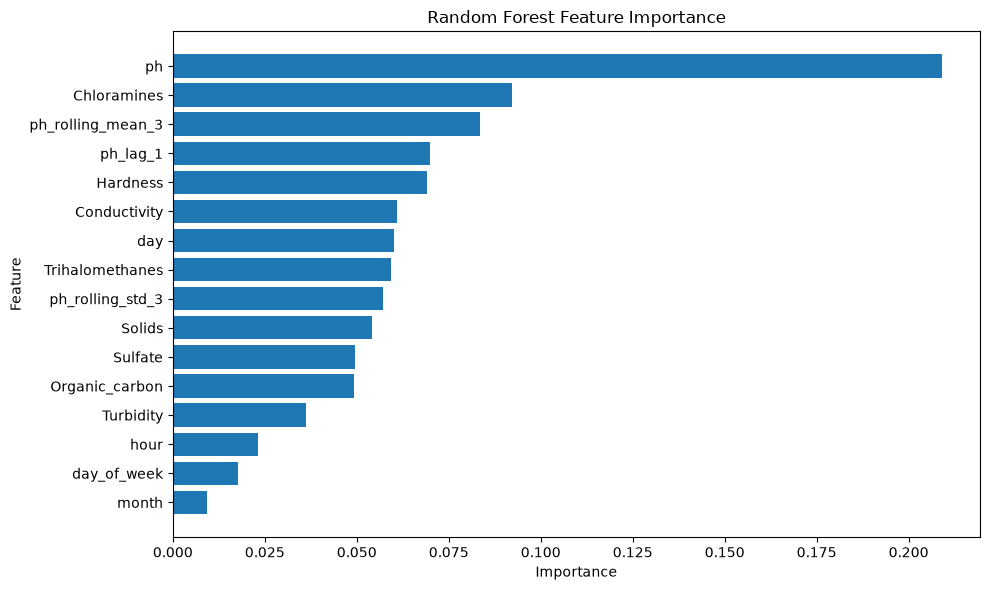

In [27]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [28]:
sensor_cols = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

X_anomaly = test_df[sensor_cols]

X_anomaly_imp = final_if["imputer"].transform(
    X_anomaly
)

if_predictions = final_if["model"].predict(
    X_anomaly_imp
)

if_scores = final_if["model"].decision_function(
    X_anomaly_imp
)

anomaly_results = test_df.copy()

anomaly_results["anomaly_flag"] = if_predictions
anomaly_results["anomaly_score"] = if_scores

print(
    "Detected anomalies:",
    np.sum(if_predictions == -1)
)

Detected anomalies: 12


In [29]:
strongest_anomalies = anomaly_results[
    anomaly_results["anomaly_flag"] == -1
].sort_values(
    "anomaly_score"
).head(20)

strongest_anomalies[
    [
        "timestamp",
        "ph",
        "Hardness",
        "Solids",
        "Conductivity",
        "Turbidity",
        "anomaly_score"
    ]
]

,timestamp,ph,Hardness,Solids,Conductivity,Turbidity,anomaly_score
433,2025-05-15 15:15:00,-0.813790,2.842641,-2.110417,0.259432,-0.676518,-0.068354
229,2025-05-07 04:15:00,-4.677519,0.563518,3.143819,1.956370,1.248195,-0.057721
484,2025-05-17 17:45:00,2.899187,-3.177404,1.736932,0.169458,0.531234,-0.037383
357,2025-05-12 11:15:00,2.248251,-2.206201,1.899379,3.089030,1.814021,-0.035085
451,2025-05-16 09:15:00,-1.534041,1.860125,2.977678,2.043262,-0.078499,-0.025129
377,2025-05-13 07:15:00,1.309277,0.787801,3.634577,-0.540021,0.765013,-0.021175
436,2025-05-15 18:15:00,-2.017621,3.332785,1.281675,0.846945,1.371070,-0.008240
412,2025-05-14 18:15:00,-1.108987,2.360793,-2.202785,-0.976828,2.211069,-0.007732
143,2025-05-03 15:00:00,-4.034262,0.761668,1.043829,0.159738,-1.820217,-0.006188
110,2025-05-02 05:45:00,4.124855,-1.370923,-0.410358,0.305793,-1.823960,-0.003233


# Limitations and Likely Failure Conditions

## Dataset Limitations

1. The original dataset did not contain real timestamps.
2. Timestamps were synthetically generated for temporal analysis.
3. The dataset does not contain temperature measurements.
4. The dataset does not contain dissolved oxygen measurements.
5. The dataset does not contain pressure measurements.
6. Ground-truth anomaly labels are unavailable.

## Forecasting Failure Conditions

The forecasting model may produce larger errors when:

- Consecutive pH values change abruptly.
- The current observation is substantially different from recent observations.
- The available lag and rolling features do not capture the underlying change.
- Conditions represented in the test data differ from patterns learned during training.
- Synthetic temporal ordering does not represent real environmental dynamics.

## Anomaly Detection Failure Conditions

The Isolation Forest may flag observations that are statistically unusual but environmentally valid.

It may also fail to detect subtle anomalies that are not sufficiently different from the learned distribution.

Because ground-truth anomaly labels are unavailable, these outputs should be treated as candidate anomalies requiring domain interpretation rather than confirmed environmental events.

## Feature Importance Limitation

Random Forest feature importance indicates the relative contribution of features within the trained model. It does not establish causal relationships between water-quality variables and future pH.

## Overall Limitation

The current system should be considered a prototype evaluated on a water-potability dataset with synthetically generated temporal information. Validation on real timestamped underwater sensor data is required before drawing conclusions about real-world underwater environmental monitoring.